In [61]:
#Import libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [62]:
#downloading multiple tickers
multi_data = yf.download(["SUNPHARMA.NS",'HINDUNILVR.NS','M&M.NS','IOC.NS','HDFCBANK.NS'], start = "2018-01-01", end="2023-12-31")


[*********************100%***********************]  5 of 5 completed


In [63]:
# Calculate returns
close_prices= multi_data["Close"]
returns = close_prices.pct_change()
rev_returns = returns.dropna()


In [64]:
print(rev_returns.head())
rev_returns.shape
returns.isna().sum()

Ticker      HDFCBANK.NS  HINDUNILVR.NS    IOC.NS    M&M.NS  SUNPHARMA.NS
Date                                                                    
2018-01-02     0.009625      -0.004388 -0.009104  0.011079     -0.003310
2018-01-03    -0.010521       0.008778 -0.000259  0.002656     -0.005418
2018-01-04     0.003913       0.001407  0.002589  0.001457      0.021351
2018-01-05     0.001989       0.003180 -0.008908  0.000463     -0.004215
2018-01-08    -0.001610       0.008736  0.012244  0.004694      0.022203


Ticker
HDFCBANK.NS      1
HINDUNILVR.NS    1
IOC.NS           1
M&M.NS           1
SUNPHARMA.NS     1
dtype: int64

In [65]:
mean_returns= rev_returns[['HDFCBANK.NS','HINDUNILVR.NS','IOC.NS','M&M.NS','SUNPHARMA.NS']].mean()
ann_mean = mean_returns*252             #annualizing mean returns
cov_matrix= rev_returns.cov()
ann_cov = cov_matrix*252
print(ann_mean)
print(ann_cov)


Ticker
HDFCBANK.NS      0.143699
HINDUNILVR.NS    0.158093
IOC.NS           0.127519
M&M.NS           0.206509
SUNPHARMA.NS     0.185946
dtype: float64
Ticker         HDFCBANK.NS  HINDUNILVR.NS    IOC.NS    M&M.NS  SUNPHARMA.NS
Ticker                                                                     
HDFCBANK.NS       0.064757       0.016926  0.021831  0.035046      0.015360
HINDUNILVR.NS     0.016926       0.054095  0.011736  0.017227      0.013435
IOC.NS            0.021831       0.011736  0.092239  0.032348      0.020088
M&M.NS            0.035046       0.017227  0.032348  0.106962      0.026337
SUNPHARMA.NS      0.015360       0.013435  0.020088  0.026337      0.086734


In [66]:
rf = 0.073           # risk-free rate.
n = 10000
port_ret, port_vol, port_sharpe, all_weights = [], [], [], []
np.random.seed(42)
for i in range(n):
    w = np.random.random(5)
    w = w/w.sum()                        # weights sum to 1
    r = np.dot(w,ann_mean)                       
    v = np.sqrt(np.dot(w.T,np.dot(w,ann_cov)))                          
    s = (r-rf)/v                          # Sharpe ratio
    port_ret.append(r)
    port_vol.append(v)
    port_sharpe.append(s)
    all_weights.append(w)

In [67]:
# Lists to array
port_ret= np.array(port_ret)
port_sharpe= np.array(port_sharpe)
port_vol= np.array(port_vol)
all_weights= np.array(all_weights)
print(port_ret.shape)
print( all_weights.shape)

(10000,)
(10000, 5)


               Min Volatility  Max Sharpe
Ticker                                   
HDFCBANK.NS              23.9         7.0
HINDUNILVR.NS            36.9        33.8
IOC.NS                   15.4         2.0
M&M.NS                    2.9        26.1
SUNPHARMA.NS             21.0        31.0

                Min Volatility  Max Sharpe
Return (%)               15.72       17.78
Volatility (%)           17.15       18.95
Sharpe ratio              0.49        0.55


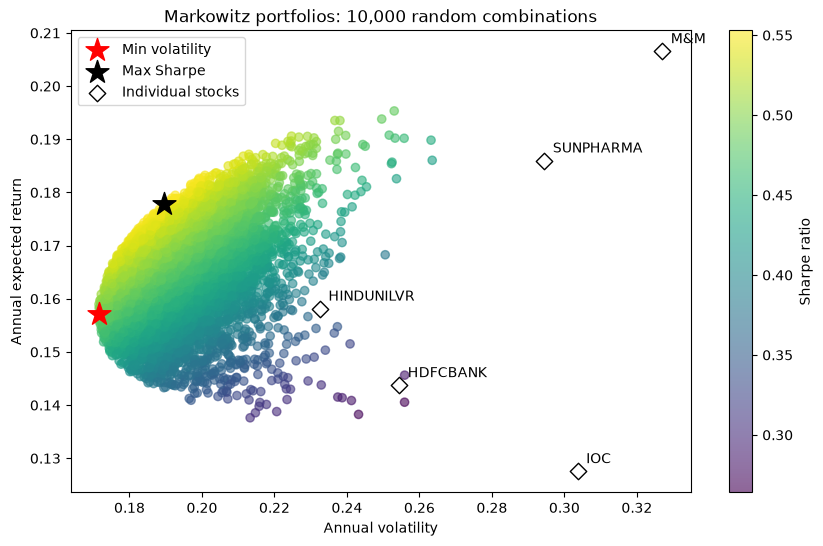

In [68]:
min_idx = np.argmin(port_vol)
max_idx = np.argmax(port_sharpe)

# Each stock's annual volatility = sqrt of the diagonal of the covariance matrix
vols = np.sqrt(np.diag(ann_cov))
tickers = ann_mean.index

# Table 1: weights (%) of the two optimal portfolios
weights_table = pd.DataFrame({
    "Min Volatility": all_weights[min_idx] * 100,
    "Max Sharpe": all_weights[max_idx] * 100
}, index=tickers).round(1)

# Table 2: summary figures of the two portfolios
summary_table = pd.DataFrame({
    "Min Volatility": [port_ret[min_idx]*100, port_vol[min_idx]*100, port_sharpe[min_idx]],
    "Max Sharpe":     [port_ret[max_idx]*100, port_vol[max_idx]*100, port_sharpe[max_idx]]
}, index=["Return (%)", "Volatility (%)", "Sharpe ratio"]).round(2)

print(weights_table)
print()
print(summary_table)

# Chart
plt.figure(figsize=(10, 6))
plt.scatter(port_vol, port_ret, c=port_sharpe, alpha=0.6)
plt.colorbar(label="Sharpe ratio")

# The two optimal portfolios
plt.scatter(port_vol[min_idx], port_ret[min_idx], marker="*", s=300,
            color="red", label="Min volatility")
plt.scatter(port_vol[max_idx], port_ret[max_idx], marker="*", s=300,
            color="black", label="Max Sharpe")

# The individual stocks, each labelled with its name
plt.scatter(vols, ann_mean, marker="D", s=70, color="white",
            edgecolors="black", label="Individual stocks")
for name, x, y in zip(tickers, vols, ann_mean):
    plt.annotate(name.replace(".NS", ""), (x, y), xytext=(6, 6),
                 textcoords="offset points")

plt.xlabel("Annual volatility")
plt.ylabel("Annual expected return")
plt.title("Markowitz portfolios: 10,000 random combinations")
plt.legend()
plt.show()

In [69]:
# Weights of the minimum volatality & maximum Sharpe
portfolios = {"Min Volatility": all_weights[min_idx],
              "Max Sharpe": all_weights[max_idx]}

vols = np.sqrt(np.diag(ann_cov))
vol_grid = np.outer(vols, vols)

corr = ann_cov/vol_grid              
shock = 0.5              
stressed_corr = corr + shock*(1-corr)     
stressed_cov = stressed_corr*np.outer(vols,vols)      

rows = []
for name, w in portfolios.items():
    ret = np.dot(w, ann_mean)                               
    base_vol = np.sqrt(np.dot(w, np.dot(ann_cov, w)))
    stress_vol = np.sqrt(np.dot(w, np.dot(stressed_cov, w)))                                      
    base_sharpe = (ret - rf) / base_vol
    stress_sharpe = (ret - rf) / stress_vol                                   
    rows.append([name, base_vol*100, stress_vol*100,
                 (stress_vol/base_vol - 1)*100, base_sharpe, stress_sharpe])

shock_table = pd.DataFrame(rows, columns=["Portfolio", "Base vol (%)", "Stressed vol (%)",
                                          "Vol increase (%)", "Base Sharpe", "Stressed Sharpe"]).round(2)
print(shock_table)

        Portfolio  Base vol (%)  Stressed vol (%)  Vol increase (%)  \
0  Min Volatility         17.15             22.29             29.94   
1      Max Sharpe         18.95             23.87             26.01   

   Base Sharpe  Stressed Sharpe  
0         0.49             0.38  
1         0.55             0.44  


In [70]:
covid = rev_returns.loc["2020-01-20":"2020-03-23"]    

rows = []
# The two portfolios
for name, w in portfolios.items():
    daily = covid.dot(w)                  
    cumm = (1 + daily).prod() - 1                           
    worst = daily.min()        
    rows.append([name, cumm*100, worst*100])

# Each stock
for t in covid.columns:
    cumm = (1 + covid[t]).prod() - 1                           
    worst = covid[t].min()
    rows.append([t, cumm*100, worst*100])

covid_table = pd.DataFrame(rows, columns=["Portfolio / Stock", "Cumulative return (%)",
                                          "Worst day (%)"]).round(2)
print(covid_table)

  Portfolio / Stock  Cumulative return (%)  Worst day (%)
0    Min Volatility                 -25.44          -9.88
1        Max Sharpe                 -29.07          -9.84
2       HDFCBANK.NS                 -39.64         -12.61
3     HINDUNILVR.NS                  -9.25          -8.87
4            IOC.NS                 -30.92          -9.29
5            M&M.NS                 -48.46          -9.30
6      SUNPHARMA.NS                 -28.10         -11.16
